# 04 Models – Uyazi
**Goal:** train three models for each vaccine (H1N1 and seasonal) and compare them with 5-fold cross-validated ROC AUC.

**Models:** logistic regression (simple, easy to explain), random forest, gradient boosting.

**Rules (same as the cleaning notebook):**
1. `clean()` from `src/cleaning.py` does the text cleaning, flags and ordered columns, but leaves **numeric gaps empty**.
2. The fill for numeric gaps happens **inside the Pipeline**, so it is re-learned from the training part of every CV fold. This is the Sprint 2 fix promised in the Sprint 1 notes.
3. The test set is not touched here. It is only used once, at the very end of the project.

In [20]:
import sys
sys.path.append("..")
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from src.cleaning import TARGETS, ID_COL, tidy_text, rare_levels, clean

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

train_X = pd.read_csv("../data/training_set_features.csv")
train_y = pd.read_csv("../data/training_set_labels.csv")
raw = train_X.merge(train_y, on=ID_COL, validate="one_to_one")
print("raw training data:", raw.shape)

raw training data: (26707, 38)


## 1. Prepare features
`clean()` leaves numeric gaps empty on purpose. The only thing learned from the data here is the list of common job codes, and it uses counts only, never the vaccination labels.

In [21]:
keep = rare_levels(tidy_text(raw))
data = clean(raw, keep)

y = data[TARGETS]
X = data.drop(columns=[ID_COL, *TARGETS])

cat_cols = X.select_dtypes(exclude="number").columns.tolist()
num_cols = X.select_dtypes(include="number").columns.tolist()
X[cat_cols] = X[cat_cols].astype(object)

print("features:", X.shape, "| text columns:", len(cat_cols), "| numeric columns:", len(num_cols))
print("numeric gaps still to be filled by the Pipeline:", int(X[num_cols].isnull().sum().sum()))
print("text gaps (should be 0):", int(X[cat_cols].isnull().sum().sum()))
print("target rates:", y.mean().round(3).to_dict())

features: (26707, 49) | text columns: 12 | numeric columns: 37
numeric gaps still to be filled by the Pipeline: 29049
text gaps (should be 0): 0
target rates: {'h1n1_vaccine': 0.212, 'seasonal_vaccine': 0.466}


## 2. Pipelines
Every model sits in the same kind of Pipeline: **fill numeric gaps (most frequent value) → encode → model**.
- Logistic regression needs scaled numbers; the tree models do not.
- Text columns become 0/1 columns (one-hot). Unknown categories in new data are ignored instead of crashing.

In [22]:
def make_pipeline(model, scale):
    num_steps = [("fill", SimpleImputer(strategy="most_frequent"))]
    if scale:
        num_steps.append(("scale", StandardScaler()))
    prep = ColumnTransformer(
        [("num", Pipeline(num_steps), num_cols),
         ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols)],
        sparse_threshold=0)
    return Pipeline([("prep", prep), ("model", model)])

def get_models():
    return {
        "Logistic regression": make_pipeline(LogisticRegression(max_iter=2000), scale=True),
        "Random forest": make_pipeline(RandomForestClassifier(
            n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE), scale=False),
        "Gradient boosting": make_pipeline(HistGradientBoostingClassifier(
            learning_rate=0.05, max_iter=300, max_leaf_nodes=15, l2_regularization=1.0,
            random_state=RANDOM_STATE), scale=False),
    }

print(list(get_models()))

['Logistic regression', 'Random forest', 'Gradient boosting']


## 3. Cross-validation (5 folds, ROC AUC)
The same folds are used for every model, so the scores are directly comparable. Out-of-fold predictions are kept for the ROC curves.

In [23]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows, oof = [], {}

for target in TARGETS:
    for name in get_models():
        preds = np.zeros(len(X))
        for fold, (tr, va) in enumerate(cv.split(X, y[target]), start=1):
            pipe = get_models()[name]                      # fresh, unfitted copy for each fold
            pipe.fit(X.iloc[tr], y[target].iloc[tr])
            preds[va] = pipe.predict_proba(X.iloc[va])[:, 1]
            rows.append({"target": target, "model": name, "fold": fold,
                         "auc": roc_auc_score(y[target].iloc[va], preds[va])})
        oof[(target, name)] = preds
        print(f"done: {target:17s} {name}")

cv_scores = pd.DataFrame(rows)

done: h1n1_vaccine      Logistic regression
done: h1n1_vaccine      Random forest
done: h1n1_vaccine      Gradient boosting
done: seasonal_vaccine  Logistic regression
done: seasonal_vaccine  Random forest
done: seasonal_vaccine  Gradient boosting


In [24]:
summary = (cv_scores.groupby(["target", "model"])["auc"].agg(["mean", "std"]).round(3)
           .rename(columns={"mean": "ROC AUC (mean)", "std": "std over folds"}))
summary

ROC AUC (mean)  std over folds
target           model                                              
h1n1_vaccine     Gradient boosting             0.871           0.005
                 Logistic regression           0.862           0.004
                 Random forest                 0.864           0.005
seasonal_vaccine Gradient boosting             0.863           0.004
                 Logistic regression           0.856           0.003
                 Random forest                 0.857           0.003

In [25]:
wide = cv_scores.pivot_table(index=["target", "fold"], columns="model", values="auc")
for target in TARGETS:
    diff = wide.loc[target, "Gradient boosting"] - wide.loc[target, "Logistic regression"]
    print(target, "| boosting minus logistic per fold:", diff.round(3).tolist())

h1n1_vaccine | boosting minus logistic per fold: [0.009, 0.01, 0.008, 0.009, 0.009]
seasonal_vaccine | boosting minus logistic per fold: [0.006, 0.007, 0.008, 0.006, 0.01]


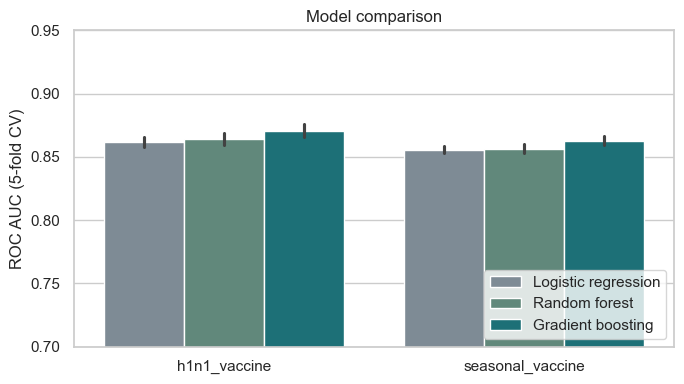

In [26]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=cv_scores, x="target", y="auc", hue="model", errorbar="sd", ax=ax,
            palette=["#7A8B99", "#5B8E7D", "#0E7C86"])
ax.set_ylim(0.7, 0.95); ax.set_xlabel(""); ax.set_ylabel("ROC AUC (5-fold CV)")
ax.set_title("Model comparison"); ax.legend(title="", loc="lower right")
plt.tight_layout(); plt.show()

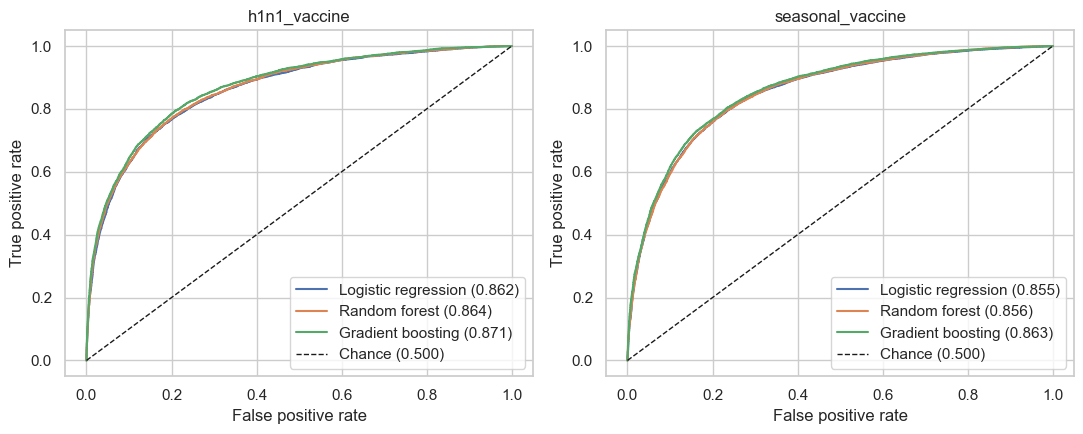

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, target in zip(axes, TARGETS):
    for name in get_models():
        fpr, tpr, _ = roc_curve(y[target], oof[(target, name)])
        auc = roc_auc_score(y[target], oof[(target, name)])
        ax.plot(fpr, tpr, label=f"{name} ({auc:.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="Chance (0.500)")
    ax.set_title(target); ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

## 4. What does the simple model say?
Coefficients of the logistic regression fitted on all training rows (numbers are scaled, so sizes are comparable). Positive = more likely to vaccinate. Associations, not causes.

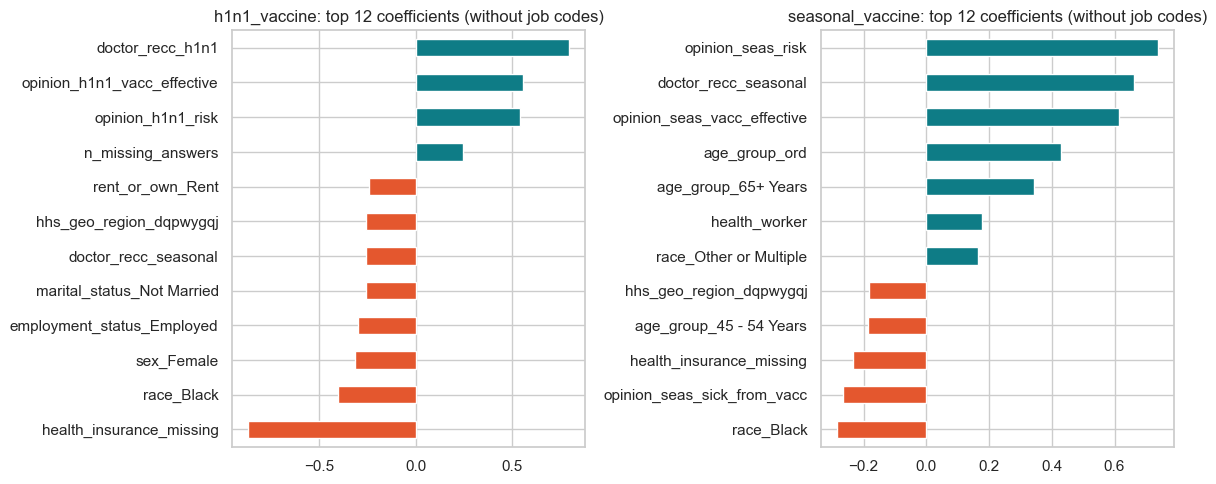

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, target in zip(axes, TARGETS):
    pipe = get_models()["Logistic regression"].fit(X, y[target])
    names = pipe.named_steps["prep"].get_feature_names_out()
    coef = pd.Series(pipe.named_steps["model"].coef_[0], index=names)
    coef = coef[~coef.index.str.contains("employment_industry|employment_occupation")]
    top = coef.reindex(coef.abs().sort_values(ascending=False).head(12).index).sort_values()
    top.index = [i.replace("num__", "").replace("cat__", "") for i in top.index]
    top.plot.barh(ax=ax, color=["#E4572E" if v < 0 else "#0E7C86" for v in top])
    ax.set_title(f"{target}: top 12 coefficients (without job codes)")
plt.tight_layout(); plt.show()

### Reading the coefficients.

Logistic regression fitted on all training rows. Numeric features are scaled, so bar lengths are roughly comparable. **Teal = more likely to be vaccinated, orange = less likely**, holding the other features fixed. These are associations, not causes.

**H1N1 vaccine**
- **Doctor's recommendation** is the largest positive bar (`doctor_recc_h1n1`), followed by **belief that the vaccine is effective** and **perceived risk of H1N1**. This supports H6, H1 and H4.
- **Skipping the health-insurance question** is the largest negative bar (`health_insurance_missing`). It confirms the Sprint 1 finding (11% uptake if skipped vs 30% if answered) and shows the missing-value flag carries signal.
- Smaller negative bars: renting, not married, employed, female, Black, and one anonymised region code. They are weaker than the attitude and doctor variables.
- `doctor_recc_seasonal` is negative for H1N1. This is most likely because it overlaps with `doctor_recc_h1n1`: once the H1N1 recommendation is in the model, the seasonal one adds little. We should not read it as "a seasonal recommendation lowers H1N1 uptake".
- `n_missing_answers` is slightly positive although `health_insurance_missing` is negative. The two features overlap, so we should not interpret this bar on its own.

**Seasonal vaccine**
- The strongest bars are **perceived risk of seasonal flu**, **doctor's recommendation** and **belief in effectiveness**, the same pattern as H1N1 (H1, H4, H6).
- **Age** is clearly positive (`age_group_ord`, `age_group_65+ Years`), while ages 45–54 are slightly negative. This matches the EDA finding that age matters for seasonal flu much more than for H1N1 (H2). Health workers are also more likely to be vaccinated.
- **Worry about side effects** (`opinion_seas_sick_from_vacc`) is negative, which supports H1.
- `health_insurance_missing` is negative again, but weaker than for H1N1.

**What is not in the top 12:** preventive behaviours (H3), and income or education (H2). Their coefficients are smaller than the beliefs and doctor-recommendation variables. This does not prove they don't matter. It means the model relies on them less once beliefs and recommendations are included.

**Cautions**
- Associations only: a survey cannot show why someone was or wasn't vaccinated.
- `race_Black` is negative in both models after accounting for the other features. Possible reasons (access, trust, outreach, sampling) cannot be tested with this data, so we report it as an association only.
- Features overlap (for example `age_group_ord` and the age-group dummies), so single coefficients are less reliable than the overall pattern.
- The anonymised region and job codes cannot be interpreted. Permutation importance on the best model (Sprint 3) will give one score per original question instead of per category.

## Results (fill in after running)
| Model | H1N1 AUC | Seasonal AUC |
|---|---|---|
| Logistic regression |0.862 | 0.856|
| Random forest |0.864 |0.857 |
| Gradient boosting | **0.871**| **0.863**|

The spread over folds (std) is 0.003 to 0.005 for every model.


**Honest scores:** the Sprint 1 score (about 0.86 for H1N1) used a mode fill learned outside the folds. With the fill re-learned in every fold, logistic regression still scores 0.862, so that shortcut did not inflate the result.
- **Best model:** gradient boosting is best for both vaccines. Its lead over the next-best model is about 0.006 to 0.007 AUC, which is roughly 1.5 to 2 times the spread over folds. That is a small but fairly consistent edge, not a large one.
- **Simple model is close:** logistic regression is within 0.01 AUC of the best model. It is easier to explain, so it remains a good choice for communicating results.
- **Coefficients match the hypotheses:** doctor's recommendation, belief in vaccine effectiveness and perceived risk are the strongest positive survey variables for both vaccines (H1, H4, H6). Age matters for seasonal flu only (H2). Skipping the insurance question is clearly negative for H1N1, which confirms the missing-value flag. Rare job codes produced the largest bars but are not interpretable, so they are excluded from the interpretation. See the note under the second coefficient chart.
- **Limits:** associations, not causes. Coefficients of overlapping features should not be read one by one.

**Next:** light tuning of gradient boosting (Sprint 2), then permutation importance and the dashboard (Sprint 3). The test set is used only once, at the end.